# 🩻 Radon Transform & CT Reconstruction

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/negarsh76/Digital-Image-Processing/blob/main/notebooks/05_radon_ct_reconstruction.ipynb)

Computed tomography from first principles. A **Shepp–Logan phantom** is projected into a **sinogram**, then reconstructed with **plain back-projection**, a **filtered back-projection (FBP)** written from scratch with Ram-Lak / Shepp–Logan / Hamming filters, and the iterative **SART** algorithm. The last section measures how image quality depends on the number of projection angles, which is the core trade-off in low-dose CT.

In [1]:
# On Colab, uncomment:
# !pip -q install scikit-image opencv-python-headless

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from skimage import data, img_as_float
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "image.cmap": "gray"})
ASSETS = Path("../assets"); ASSETS.mkdir(exist_ok=True)

def show(images, titles, ncols=None, figsize=None, save=None, cmap="gray"):
    """Plot a row/grid of images with titles; optionally save to assets/."""
    n = len(images); ncols = ncols or n; nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize or (3.2 * ncols, 3.2 * nrows))
    for ax, im, t in zip(np.ravel(axes), images, titles):
        ax.imshow(im, cmap=None if im.ndim == 3 else cmap); ax.set_title(t); ax.axis("off")
    for ax in np.ravel(axes)[n:]: ax.axis("off")
    fig.tight_layout()
    if save: fig.savefig(ASSETS / save, bbox_inches="tight", dpi=120)
    plt.show()

def psnr(ref, img):
    mse = np.mean((np.asarray(ref, float) - np.asarray(img, float)) ** 2)
    return 10 * np.log10(1.0 / mse) if mse > 0 else np.inf


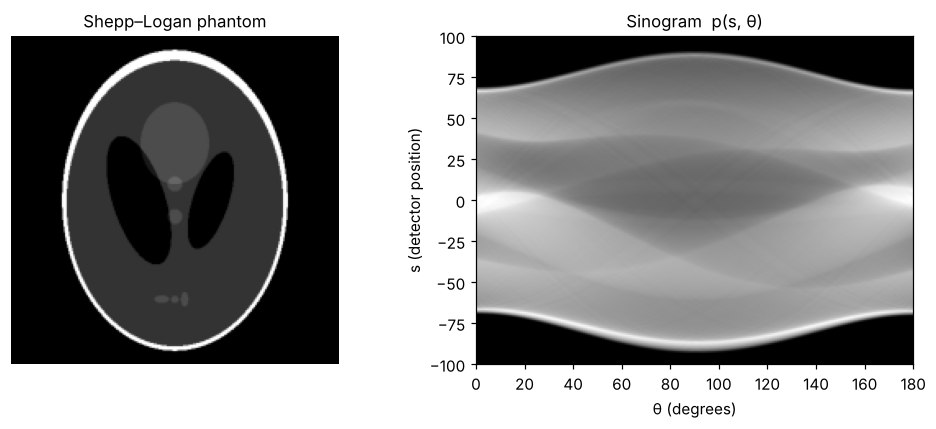

In [3]:
from skimage.data import shepp_logan_phantom
from skimage.transform import radon, iradon, iradon_sart, rescale, rotate

phantom = rescale(shepp_logan_phantom(), 0.5, anti_aliasing=True)     # 200×200
theta = np.linspace(0., 180., 180, endpoint=False)
sinogram = radon(phantom, theta=theta)

fig, (a, b) = plt.subplots(1, 2, figsize=(9, 4))
a.imshow(phantom); a.set_title("Shepp–Logan phantom"); a.axis("off")
b.imshow(sinogram, aspect="auto", extent=(0, 180, -sinogram.shape[0] / 2, sinogram.shape[0] / 2))
b.set_title("Sinogram  p(s, θ)"); b.set_xlabel("θ (degrees)"); b.set_ylabel("s (detector position)")
fig.tight_layout(); fig.savefig(ASSETS / "sinogram.png", dpi=120); plt.show()

## Projections are line integrals
$$p(s,\theta)=\iint f(x,y)\,\delta(x\cos\theta + y\sin\theta - s)\,dx\,dy$$
Each column of the sinogram is the phantom **rotated by θ and summed along one axis**. We can check that directly:

In [4]:
n = phantom.shape[0]
col = lambda ang: rotate(phantom, -ang, center=(n / 2, n / 2), preserve_range=True).sum(axis=0)   # our own projection
for ang in (0, 45, 90):
    i = int(ang)
    ours = col(ang); ref = sinogram[:, i]
    err = np.linalg.norm(ours - ref) / np.linalg.norm(ref)
    print(f"θ = {ang:3d}°  relative L2 error vs skimage.radon: {err:.1e}")

θ =   0°  relative L2 error vs skimage.radon: 0.0e+00
θ =  45°  relative L2 error vs skimage.radon: 9.2e-16
θ =  90°  relative L2 error vs skimage.radon: 0.0e+00


## Filtered back-projection from scratch
Plain back-projection smears every projection back across the image, which gives a blurry $1/r$ point-spread. FBP fixes this by first filtering each projection with a ramp $|\omega|$, optionally apodised by a window, and then back-projecting.

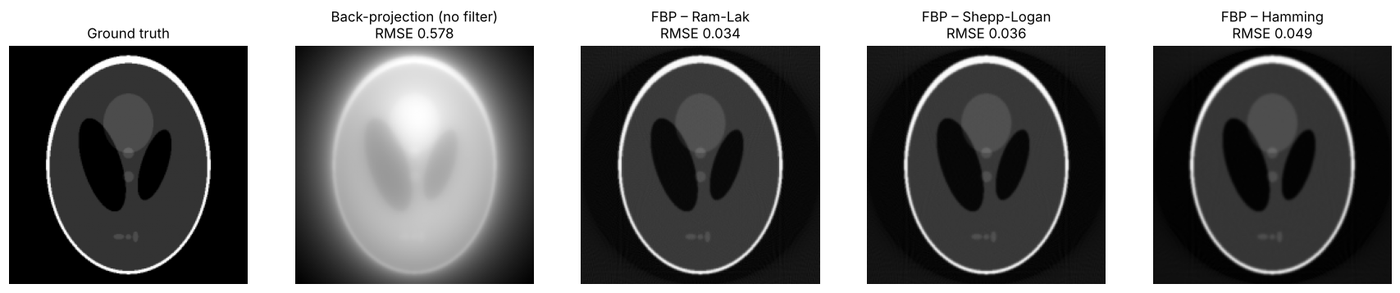

In [5]:
def fbp(sino, theta, window="ramp"):
    n_det, n_ang = sino.shape
    size = max(64, int(2 ** np.ceil(np.log2(2 * n_det))))            # zero-pad to avoid wrap-around
    freqs = np.fft.fftfreq(size)
    filt = 2 * np.abs(freqs)                                           # Ram-Lak
    w = freqs / freqs.max() * np.pi                                    # normalised frequency in [-π, π]
    if window == "shepp-logan": filt *= np.sinc(freqs / (2 * np.abs(freqs).max()))
    elif window == "hamming":   filt *= 0.54 + 0.46 * np.cos(w)
    elif window == "none":      filt = np.ones_like(filt)              # unfiltered back-projection
    padded = np.zeros((size, n_ang)); padded[:n_det] = sino
    filtered = np.real(np.fft.ifft(np.fft.fft(padded, axis=0) * filt[:, None], axis=0))[:n_det]

    N = n_det; recon = np.zeros((N, N))
    c = N // 2; xs = np.arange(N) - c
    X, Y = np.meshgrid(xs, xs)                                         # X = column, Y = row offset
    for i, t in enumerate(np.deg2rad(theta)):
        s = X * np.cos(t) - Y * np.sin(t) + c                          # detector coordinate for each pixel
        recon += np.interp(s.ravel(), np.arange(n_det), filtered[:, i], left=0, right=0).reshape(N, N)
    recon *= np.pi / (2 * n_ang)
    # crop to the phantom size
    off = (N - phantom.shape[0]) // 2
    return recon[off:off + phantom.shape[0], off:off + phantom.shape[1]]

rmse = lambda x: np.sqrt(np.mean((x - phantom) ** 2))
recons = {w: fbp(sinogram, theta, w) for w in ["none", "ramp", "shepp-logan", "hamming"]}
recons["none"] *= phantom.max() / recons["none"].max()               # rescale the blurry one for display
titles = {"none": "Back-projection (no filter)", "ramp": "FBP – Ram-Lak", "shepp-logan": "FBP – Shepp-Logan", "hamming": "FBP – Hamming"}
show([phantom] + list(recons.values()), ["Ground truth"] + [f"{titles[k]}\nRMSE {rmse(v):.3f}" for k, v in recons.items()],
     ncols=5, save="fbp_filters.png")

In [6]:
ref = iradon(sinogram, theta=theta, filter_name="ramp")
print(f"Our FBP (ramp) vs skimage.iradon: RMSE between them = {np.sqrt(np.mean((recons['ramp'] - ref) ** 2)):.4f}")
print(f"skimage.iradon RMSE vs ground truth          = {rmse(ref):.4f}")

Our FBP (ramp) vs skimage.iradon: RMSE between them = 0.0222
skimage.iradon RMSE vs ground truth          = 0.0253


## Iterative reconstruction: SART
The Simultaneous Algebraic Reconstruction Technique treats CT as solving $A\mathbf{x}=\mathbf{p}$. Each iteration back-projects the *residual* between measured and simulated projections.

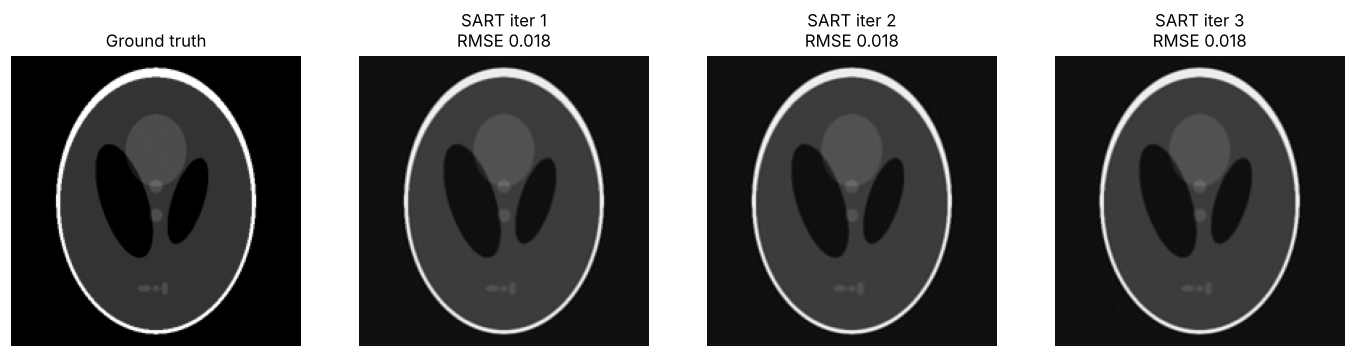

In [7]:
x = None; sart = []
for it in range(3):
    x = iradon_sart(sinogram, theta=theta, image=x); sart.append(x)
show([phantom] + sart, ["Ground truth"] + [f"SART iter {i+1}\nRMSE {rmse(s):.3f}" for i, s in enumerate(sart)], save="sart.png")

## Sparse-view CT: how many angles do we really need?
Fewer projections means a lower radiation dose but more streak artefacts. Iterative methods degrade more gracefully than FBP. This is the motivation behind modern deep-learning CT reconstruction.

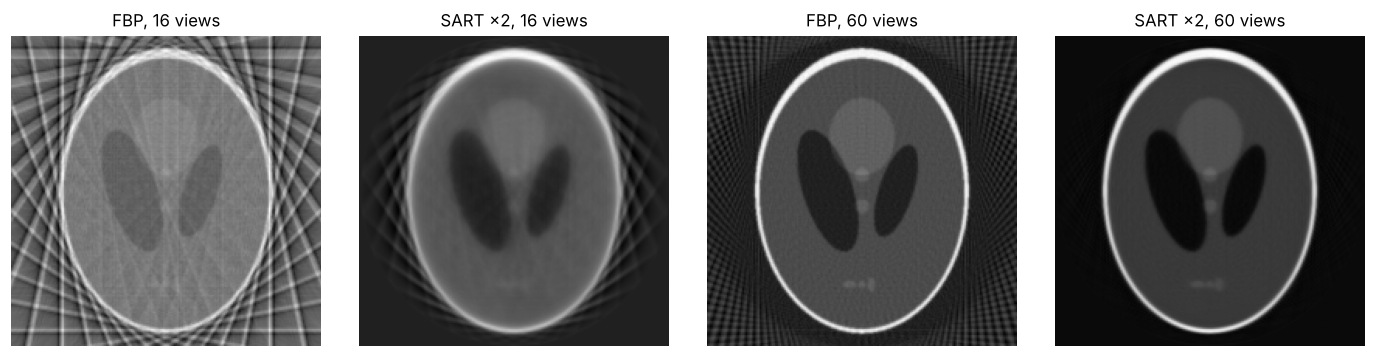

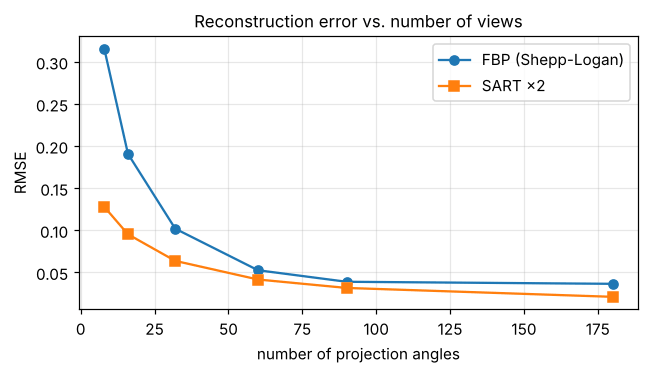

In [8]:
n_views = [8, 16, 32, 60, 90, 180]
fbp_err, sart_err, gallery = [], [], []
for n in n_views:
    th = np.linspace(0., 180., n, endpoint=False)
    sg = radon(phantom, theta=th)
    r_fbp = fbp(sg, th, "shepp-logan")
    r_sart = iradon_sart(sg, theta=th); r_sart = iradon_sart(sg, theta=th, image=r_sart)
    fbp_err.append(rmse(r_fbp)); sart_err.append(rmse(r_sart))
    if n in (16, 60): gallery += [(r_fbp, f"FBP, {n} views"), (r_sart, f"SART ×2, {n} views")]

show([g for g, _ in gallery], [t for _, t in gallery], save="sparse_view.png")
plt.figure(figsize=(6, 3.5))
plt.plot(n_views, fbp_err, "o-", label="FBP (Shepp-Logan)"); plt.plot(n_views, sart_err, "s-", label="SART ×2")
plt.xlabel("number of projection angles"); plt.ylabel("RMSE"); plt.legend(); plt.grid(alpha=.3)
plt.title("Reconstruction error vs. number of views"); plt.tight_layout()
plt.savefig(ASSETS / "views_vs_rmse.png", dpi=120); plt.show()